
# Book Recommendation System

## Построение прототипа книжного рекомендательного сервиса

**Цель проекта:** разработать и сравнить несколько алгоритмов рекомендательных систем на датасете Goodbooks-10k.

### План работы

1. Загрузка данных и разведочный анализ (EDA).
2. Неперсонализированные рекомендации (Popularity-Based).
3. Контентные рекомендации (Content-Based Filtering).
4. Коллаборативная фильтрация (Item-Based CF).
5. Матричная факторизация (SVD).
6. Оценка качества моделей: Precision@K, Recall@K, nDCG@K.
7. Гибридная система и выводы.


In [4]:

# Подключение библиотек для анализа данных

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



## Этап 1. Загрузка данных и разведочный анализ (EDA)

На данном этапе загрузим датасет Goodbooks-10k, посмотрим структуру данных, проверим пропущенные значения и дубликаты.

Затем исследуем распределение рейтингов, активность пользователей, популярность книг и наиболее распространённые теги.


In [5]:

from google.colab import files

uploaded = files.upload()


Saving archive.zip to archive (1).zip


In [6]:

import zipfile
import os

with zipfile.ZipFile("archive.zip", "r") as zip_ref:
    zip_ref.extractall("data")

print("Архив успешно распакован!")
print(os.listdir("data"))


Архив успешно распакован!
['tags.csv', 'to_read.csv', 'books.csv', 'book_tags.csv', 'ratings.csv', 'sample_book.xml']


In [7]:

# Загрузка данных в DataFrame

books = pd.read_csv("data/books.csv")
ratings = pd.read_csv("data/ratings.csv")
tags = pd.read_csv("data/tags.csv")
book_tags = pd.read_csv("data/book_tags.csv")
to_read = pd.read_csv("data/to_read.csv")


In [8]:
books = pd.read_csv("data/books.csv")

In [9]:

# Просмотр первых пяти строк таблицы books

books.head()


,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


In [10]:

# Проверка размеров датасетов

print("Books:", books.shape)
print("Ratings:", ratings.shape)
print("Tags:", tags.shape)
print("Book tags:", book_tags.shape)
print("To read:", to_read.shape)


Books: (10000, 23)
Ratings: (981756, 3)
Tags: (34252, 2)
Book tags: (999912, 3)
To read: (912705, 2)


In [11]:

# Общая информация о таблице books

books.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         10000 non-null  int64  
 1   book_id                    10000 non-null  int64  
 2   best_book_id               10000 non-null  int64  
 3   work_id                    10000 non-null  int64  
 4   books_count                10000 non-null  int64  
 5   isbn                       9300 non-null   object 
 6   isbn13                     9415 non-null   float64
 7   authors                    10000 non-null  object 
 8   original_publication_year  9979 non-null   float64
 9   original_title             9415 non-null   object 
 10  title                      10000 non-null  object 
 11  language_code              8916 non-null   object 
 12  average_rating             10000 non-null  float64
 13  ratings_count              10000 non-null  int6

In [12]:

# Подсчёт пропущенных значений в таблице books

books.isna().sum().sort_values(ascending=False)


,0
language_code,1084
isbn,700
isbn13,585
original_title,585
original_publication_year,21
best_book_id,0
id,0
work_id,0
books_count,0
book_id,0



### Вывод по анализу пропущенных значений

В таблице `books` содержится 10 000 книг и 23 признака.

В ходе анализа обнаружены пропущенные значения в пяти столбцах:

- `language_code` — 1 084 пропуска;
- `isbn` — 700 пропусков;
- `isbn13` — 585 пропусков;
- `original_title` — 585 пропусков;
- `original_publication_year` — 21 пропуск.

Ключевые признаки (`id`, `title`, `authors`, `average_rating`) полностью заполнены.

**Вывод:** обнаруженные пропуски не препятствуют построению базовой рекомендательной системы. На данном этапе удалять строки не требуется. При построении контентной модели пропущенные названия можно заменить значениями из столбца `title`.


In [13]:

# Проверка дубликатов в таблице ratings

duplicates = ratings.duplicated(
    subset=["user_id", "book_id"]
).sum()

print("Количество дубликатов:", duplicates)


Количество дубликатов: 2278


In [14]:

# Просмотр повторяющихся оценок

duplicate_rows = ratings[
    ratings.duplicated(
        subset=["user_id", "book_id"],
        keep=False
    )
]

duplicate_rows.head(10)


,book_id,user_id,rating
1170,12,40251,4
1171,12,40251,4
2473,25,32635,5
2474,25,32635,5
2717,28,9011,2
2718,28,9011,1
2946,30,24582,4
2947,30,24582,3
2958,30,31760,4
2959,30,31760,4


In [15]:

# Анализ повторных оценок пользователей

duplicate_groups = ratings.groupby(
    ["user_id", "book_id"]
)["rating"].nunique()

conflicting_ratings = (duplicate_groups > 1).sum()

print("Количество пар с разными оценками:", conflicting_ratings)




Количество пар с разными оценками: 633


In [16]:

# Объединение повторных оценок пользователей

ratings_clean = ratings.groupby(
    ["user_id", "book_id"],
    as_index=False
)["rating"].mean()

print("До очистки:", ratings.shape)
print("После очистки:", ratings_clean.shape)

print("Оставшиеся дубликаты:",
      ratings_clean.duplicated(
          subset=["user_id", "book_id"]
      ).sum())


До очистки: (981756, 3)
После очистки: (979478, 3)
Оставшиеся дубликаты: 0



### Обработка дубликатов

В исходной таблице `ratings` обнаружено 2 278 повторных записей по сочетанию `user_id` и `book_id`.

Среди повторяющихся взаимодействий выявлено 633 пары с различающимися оценками.

Для обработки дубликатов применена группировка по пользователю и книге с усреднением оценок.

В результате количество записей сократилось с 981 756 до 979 478. Повторных пар не осталось.

Для последующего анализа и моделирования используется очищенная таблица `ratings_clean`.


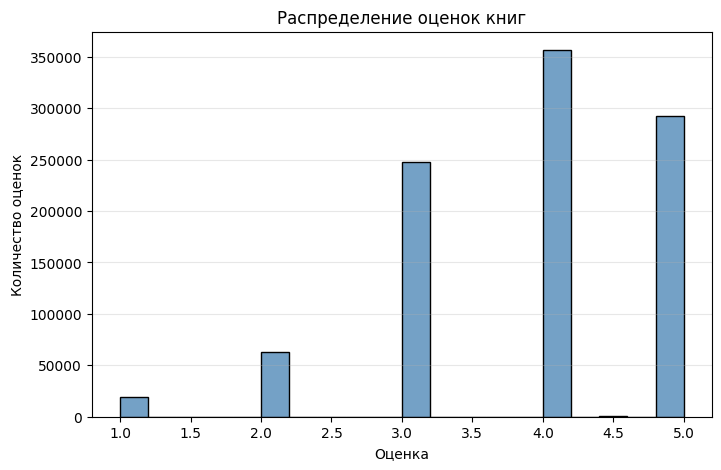

In [17]:

# Распределение оценок пользователей

plt.figure(figsize=(8, 5))

sns.histplot(
    data=ratings_clean,
    x="rating",
    bins=20,
    color="steelblue"
)

plt.title("Распределение оценок книг")
plt.xlabel("Оценка")
plt.ylabel("Количество оценок")
plt.grid(axis="y", alpha=0.3)

plt.show()



### Анализ распределения оценок

Гистограмма показывает, что распределение оценок смещено в сторону высоких значений.

Наиболее распространённая оценка-4, затем следуют оценки 5 и 3. Низкие оценки (1 и 2) встречаются значительно реже.

Оценки 4 и 5 составляют примерно две трети всех взаимодействий.

**Вывод:** пользователи преимущественно положительно оценивают книги. Это необходимо учитывать при обучении и сравнении рекомендательных моделей.

Для последующей оценки качества рекомендаций будем считать релевантными книги с рейтингом не ниже 4.

При этом высокая предсказанная оценка сама по себе не гарантирует качественную персонализированную рекомендацию.


In [18]:

# Подсчёт количества оценок каждого пользователя

user_activity = ratings_clean.groupby("user_id")["book_id"].count()

# Основные статистики активности пользователей
print(user_activity.describe())


count    53424.000000
mean        18.334045
std         26.224647
min          1.000000
25%          3.000000
50%          8.000000
75%         22.000000
max        200.000000
Name: book_id, dtype: float64


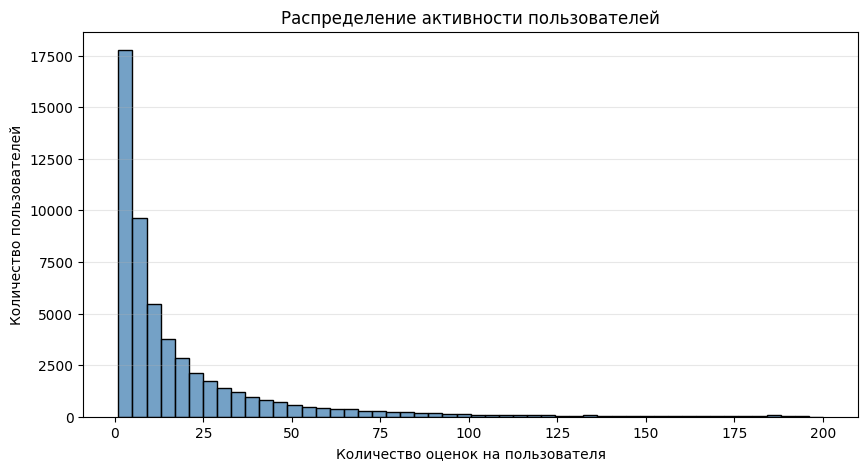

In [19]:

# Распределение активности пользователей

plt.figure(figsize=(10, 5))

sns.histplot(
    user_activity,
    bins=50,
    color="steelblue"
)

plt.title("Распределение активности пользователей")
plt.xlabel("Количество оценок на пользователя")
plt.ylabel("Количество пользователей")
plt.grid(axis="y", alpha=0.3)

plt.show()


In [20]:

# Анализ малоактивных пользователей

cold_users = (user_activity <= 5).sum()

cold_percentage = cold_users / len(user_activity) * 100

print("Всего пользователей:", len(user_activity))
print("Пользователей с 1–5 оценками:", cold_users)
print(f"Доля малоактивных пользователей: {cold_percentage:.2f}%")


Всего пользователей: 53424
Пользователей с 1–5 оценками: 20985
Доля малоактивных пользователей: 39.28%



### Вывод по анализу активности пользователей

В датасете обнаружено 53 424 пользователя.

Среднее количество оценок на пользователя составляет 18,33, при этом медиана равна 8. Это свидетельствует о неравномерном распределении пользовательской активности.

Гистограмма демонстрирует правостороннюю асимметрию: большинство пользователей имеют небольшое количество взаимодействий, а относительно небольшая группа пользователей оценила значительно больше книг.

При выбранном пороге в 5 оценок выявлено 20 985 малоактивных пользователей, что составляет 39,28% от общего количества.

**Вывод:** значительная доля пользователей имеет ограниченную историю взаимодействий, что создаёт потенциальную проблему холодного старта для коллаборативной фильтрации.

Для таких пользователей целесообразно рассмотреть гибридные рекомендации, включающие контентные модели и популярные книги.


In [21]:

# Подсчёт количества оценок для каждой книги

book_popularity = ratings_clean.groupby("book_id")["user_id"].count()

# Основные статистики популярности книг
print(book_popularity.describe())



count    10000.000000
mean        97.947800
std          5.759322
min          8.000000
25%         99.000000
50%        100.000000
75%        100.000000
max        100.000000
Name: user_id, dtype: float64


In [22]:

# Статистика популярности книг по данным Goodreads

print(books["ratings_count"].describe())


count    1.000000e+04
mean     5.400124e+04
std      1.573700e+05
min      2.716000e+03
25%      1.356875e+04
50%      2.115550e+04
75%      4.105350e+04
max      4.780653e+06
Name: ratings_count, dtype: float64


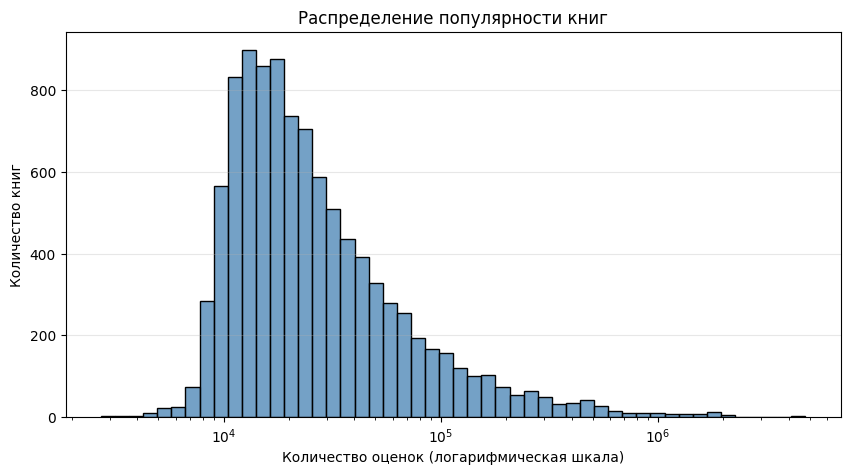

In [23]:

# Распределение популярности книг

plt.figure(figsize=(10, 5))

sns.histplot(
    data=books,
    x="ratings_count",
    bins=50,
    log_scale=True,
    color="steelblue"
)

plt.title("Распределение популярности книг")
plt.xlabel("Количество оценок (логарифмическая шкала)")
plt.ylabel("Количество книг")
plt.grid(axis="y", alpha=0.3)

plt.show()



### Вывод по анализу популярности книг

Анализ показал значительную неравномерность популярности книг.

Среднее количество оценок составляет около 54 001, тогда как медиана-21 156. Максимальное количество оценок одной книги превышает 4,7 млн.

Гистограмма с логарифмической шкалой показывает, что большинство книг имеет относительно небольшое количество оценок по сравнению с наиболее популярными произведениями.

**Вывод:** распределение популярности характеризуется выраженной правосторонней асимметрией.

Это создаёт риск смещения рекомендаций в пользу популярных книг (Popularity Bias).

Для уменьшения такого эффекта целесообразно использовать персонализированные алгоритмы, учитывающие интересы пользователей и характеристики произведений.


In [24]:

# Просмотр структуры таблиц с тегами

print("Таблица tags:")
display(tags.head())

print("Таблица book_tags:")
display(book_tags.head())


Таблица tags:


,tag_id,tag_name
0,0,-
1,1,--1-
2,2,--10-
3,3,--12-
4,4,--122-


Таблица book_tags:


,goodreads_book_id,tag_id,count
0,1,30574,167697
1,1,11305,37174
2,1,11557,34173
3,1,8717,12986
4,1,33114,12716


In [25]:

# Объединение таблиц по идентификатору тега

book_tags_merged = book_tags.merge(
    tags,
    on="tag_id",
    how="left"
)

book_tags_merged.head()


,goodreads_book_id,tag_id,count,tag_name
0,1,30574,167697,to-read
1,1,11305,37174,fantasy
2,1,11557,34173,favorites
3,1,8717,12986,currently-reading
4,1,33114,12716,young-adult


In [26]:

# Определяем 15 наиболее популярных тегов

top_tags = (
    book_tags_merged.groupby("tag_name")["count"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

display(top_tags)


,count
tag_name,
to-read,140718761
currently-reading,7507958
favorites,4503173
fiction,3688819
fantasy,3548157
young-adult,1848306
classics,1756920
books-i-own,1317235
romance,1231926


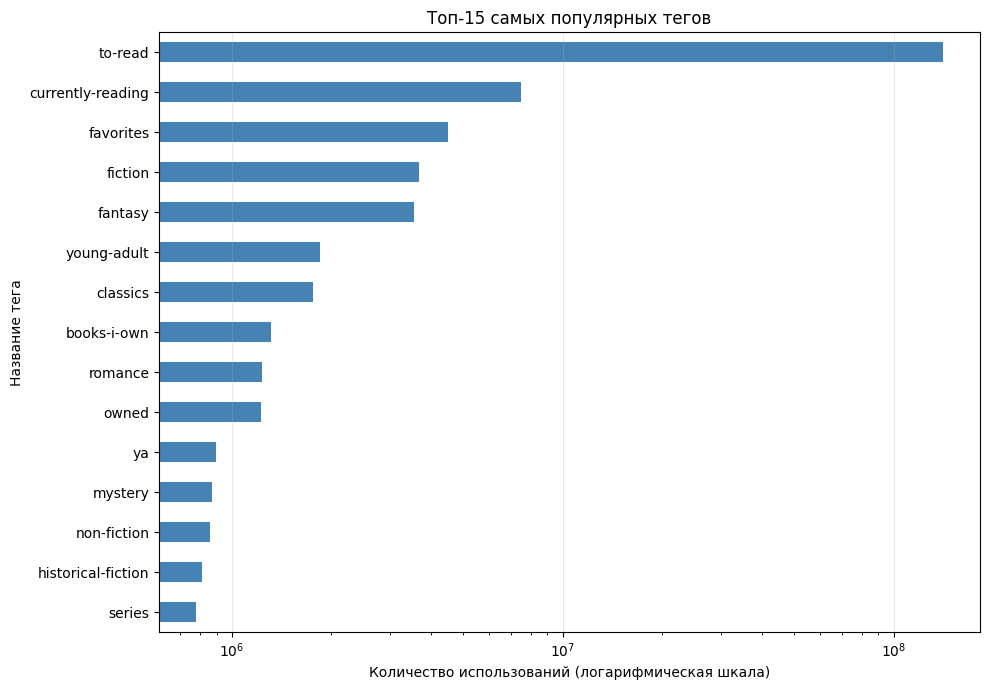

In [27]:

# Визуализация 15 самых популярных тегов

plt.figure(figsize=(10, 7))

top_tags.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.xscale("log")

plt.title("Топ-15 самых популярных тегов")
plt.xlabel("Количество использований (логарифмическая шкала)")
plt.ylabel("Название тега")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()



### Вывод по анализу тегов

Анализ показал, что наиболее распространённым тегом является `to-read`, который значительно превосходит остальные по количеству использований.

Среди популярных тегов присутствуют две категории:

- Поведенческие теги (`to-read`, `currently-reading`, `favorites`, `owned`).
- Содержательные теги (`fiction`, `fantasy`, `romance`, `mystery`, `historical-fiction`).

Поведенческие теги отражают действия пользователей, тогда как содержательные характеризуют жанры и тематику произведений.

**Вывод:** для построения контентной рекомендательной модели целесообразно использовать содержательные теги. Это позволит формировать текстовые профили книг для последующей векторизации с помощью TF-IDF и вычисления косинусного сходства.


In [28]:

# Проверка пропусков в остальных таблицах

datasets = {
    "ratings_clean": ratings_clean,
    "tags": tags,
    "book_tags": book_tags,
    "to_read": to_read
}

for name, df in datasets.items():
    print(f"\nТаблица: {name}")
    print(df.isna().sum())



Таблица: ratings_clean
user_id    0
book_id    0
rating     0
dtype: int64

Таблица: tags
tag_id      0
tag_name    0
dtype: int64

Таблица: book_tags
goodreads_book_id    0
tag_id               0
count                0
dtype: int64

Таблица: to_read
user_id    0
book_id    0
dtype: int64


In [29]:

# Проверка целостности связей между таблицами

print("Неизвестные книги в ratings_clean:",
      (~ratings_clean["book_id"].isin(books["id"])).sum())

print("Неизвестные книги в book_tags:",
      (~book_tags["goodreads_book_id"].isin(books["book_id"])).sum())

print("Неизвестные теги в book_tags:",
      (~book_tags["tag_id"].isin(tags["tag_id"])).sum())

print("Неизвестные книги в to_read:",
      (~to_read["book_id"].isin(books["id"])).sum())


Неизвестные книги в ratings_clean: 0
Неизвестные книги в book_tags: 0
Неизвестные теги в book_tags: 0
Неизвестные книги в to_read: 0


In [30]:
ratings_clean["book_id"].isin(books["id"])

,book_id
0,True
1,True
2,True
3,True
4,True
...,...
979473,True
979474,True
979475,True
979476,True



## Итоговые выводы по EDA

В ходе разведочного анализа датасета Goodbooks-10k были получены следующие результаты:

1. **Качество данных.** В таблице `books` обнаружены пропущенные значения в пяти столбцах. Основные признаки, необходимые для рекомендательных моделей, заполнены.

2. **Дубликаты.** В таблице `ratings` выявлено 2 278 повторных записей. После группировки и усреднения оценок получено 979 478 уникальных взаимодействий.

3. **Распределение рейтингов.** Пользователи значительно чаще ставят оценки 4 и 5, чем низкие оценки. Наблюдается смещение в сторону положительных рейтингов.

4. **Активность пользователей.** В датасете 53 424 пользователя. Из них 20 985 (39,28%) оценили не более пяти книг, что указывает на потенциальную проблему холодного старта.

5. **Популярность книг.** Распределение количества оценок неравномерно. Небольшая группа популярных книг получает значительно больше оценок, чем большинство остальных.

6. **Анализ тегов.** Среди наиболее распространённых тегов встречаются как поведенческие (`to-read`, `favorites`), так и содержательные (`fiction`, `fantasy`). Для контентной модели предпочтительно использовать содержательные теги.

7. **Целостность данных.** Проверка связей между таблицами не выявила неизвестных идентификаторов книг или тегов.

### Общий вывод

Датасет пригоден для построения прототипа книжной рекомендательной системы.

Основные выявленные проблемы это неравномерная активность пользователей, смещение распределения рейтингов и популярности книг.

Для сравнения качества рекомендаций планируется реализовать Popularity-Based, Content-Based Filtering, Item-Based Collaborative Filtering и SVD.


In [31]:

# Разделение данных на train и test

user_counts = ratings_clean.groupby("user_id")["book_id"].transform("count")

eligible_ratings = ratings_clean[user_counts >= 5]

test = eligible_ratings.groupby("user_id").sample(
    frac=0.2,
    random_state=42
)

train = ratings_clean.drop(index=test.index)

print("Обучающая выборка:", train.shape)
print("Тестовая выборка:", test.shape)
print("Всего записей:", len(train) + len(test))


Обучающая выборка: (793929, 3)
Тестовая выборка: (185549, 3)
Всего записей: 979478


In [32]:

# Проверка корректности разделения данных

overlap = train.index.intersection(test.index)

missing_users = (
    ~test["user_id"].isin(train["user_id"])
).sum()

total_correct = len(train) + len(test) == len(ratings_clean)

print("Совпадений между Train и Test:", len(overlap))
print("Пользователей без истории в Train:", missing_users)
print("Все записи сохранены:", total_correct)


Совпадений между Train и Test: 0
Пользователей без истории в Train: 0
Все записи сохранены: True


In [33]:

# Расчёт популярности книг на обучающей выборке

popularity_stats = train.groupby("book_id")["rating"].agg(
    mean_rating="mean",
    rating_count="count"
).reset_index()

# Минимальное количество оценок
min_ratings = 50

# Отбор и сортировка популярных книг
popular_books = popularity_stats[
    popularity_stats["rating_count"] >= min_ratings
].sort_values(
    by=["mean_rating", "rating_count"],
    ascending=[False, False]
)

display(popular_books.head(10))


,book_id,mean_rating,rating_count
6360,6361,4.819277,83
7946,7947,4.802469,81
6919,6920,4.795181,83
9565,9566,4.794521,73
3274,3275,4.787500,80
4482,4483,4.762500,80
1307,1308,4.759494,79
3752,3753,4.759036,83
5206,5207,4.743902,82
3627,3628,4.743590,78


In [34]:

# Добавляем названия книг и авторов

popular_books_named = popular_books.merge(
    books[["id", "title", "authors"]],
    left_on="book_id",
    right_on="id",
    how="left"
)

# Оставляем только необходимые столбцы
popular_books_named = popular_books_named[
    ["book_id", "title", "authors", "mean_rating", "rating_count"]
]

display(popular_books_named.head(10))


,book_id,title,authors,mean_rating,rating_count
0,6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson,4.819277,83
1,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",4.802469,81
2,6920,The Indispensable Calvin and Hobbes,Bill Watterson,4.795181,83
3,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson,4.794521,73
4,3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré",4.787500,80
5,4483,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson,4.762500,80
6,1308,A Court of Mist and Fury (A Court of Thorns an...,Sarah J. Maas,4.759494,79
7,3753,"Harry Potter Collection (Harry Potter, #1-6)",J.K. Rowling,4.759036,83
8,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,4.743902,82
9,3628,The Complete Calvin and Hobbes,Bill Watterson,4.743590,78


In [35]:

# Функция для получения Top-N популярных книг

def get_popular_books(N=5):
    recommendations = popular_books_named.head(N)
    return recommendations.reset_index(drop=True)

# Получаем 5 рекомендаций
display(get_popular_books(N=5))


,book_id,title,authors,mean_rating,rating_count
0,6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson,4.819277,83
1,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",4.802469,81
2,6920,The Indispensable Calvin and Hobbes,Bill Watterson,4.795181,83
3,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson,4.794521,73
4,3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré",4.787500,80



### Вывод по модели Popularity-Based

Реализована неперсонализированная рекомендательная модель, возвращающая Top-N книг с наиболее высокими средними оценками.

Для повышения надёжности рекомендаций установлен минимальный порог в 50 оценок на книгу.

Расчёт рейтингов выполнен исключительно на обучающей выборке, чтобы избежать утечки тестовых данных.

**Преимущества модели:**
- Простота реализации и интерпретации.
- Низкая вычислительная сложность.
- Возможность рекомендовать книги новым пользователям без истории взаимодействий.

**Недостатки модели:**
- Отсутствие персонализации.
- Недостаточное разнообразие рекомендаций.
- Возможное смещение в пользу определённых авторов и категорий книг.
- Отсутствие автоматического исключения уже прочитанных книг.

**Вывод:** Popularity-Based подходит в качестве базовой модели и решения для холодного старта, но для более точного подбора книг необходимо учитывать их содержательные характеристики и предпочтения пользователей.


In [36]:

# Исключаем поведенческие и служебные теги

non_content_tags = [
    "to-read",
    "currently-reading",
    "favorites",
    "books-i-own",
    "owned",
    "read",
    "want-to-read",
    "to-buy",
    "wishlist"
]

# Создаём таблицу с отфильтрованными тегами
content_tags = book_tags_merged[
    ~book_tags_merged["tag_name"].isin(non_content_tags)
].copy()

print("До фильтрации:", len(book_tags_merged))
print("После фильтрации:", len(content_tags))

display(content_tags.head(10))


До фильтрации: 999912
После фильтрации: 940171


,goodreads_book_id,tag_id,count,tag_name
1,1,11305,37174,fantasy
4,1,33114,12716,young-adult
5,1,11743,9954,fiction
6,1,14017,7169,harry-potter
9,1,32989,4364,ya
10,1,27199,3857,series
11,1,11590,3456,favourites
12,1,18886,3374,magic
13,1,6953,2408,childrens
14,1,22753,1881,owned-books


In [37]:

# Проверка популярных тегов после фильтрации

remaining_top_tags = (
    content_tags.groupby("tag_name")["count"]
    .sum()
    .sort_values(ascending=False)
    .head(25)
)

display(remaining_top_tags)


,count
tag_name,
fiction,3688819
fantasy,3548157
young-adult,1848306
classics,1756920
romance,1231926
ya,898334
mystery,872282
non-fiction,857901
historical-fiction,815421


In [38]:

# Дополнительные поведенческие и служебные теги

additional_tags = [
    "favourites",
    "owned-books",
    "kindle",
    "book-club",
    "currently reading",
    "to read"
]

# Расширяем первоначальный список исключений
non_content_tags = non_content_tags + additional_tags

# Повторная фильтрация исходной объединённой таблицы
content_tags = book_tags_merged[
    ~book_tags_merged["tag_name"].isin(non_content_tags)
].copy()

print("Количество записей после очистки:", len(content_tags))

# Проверяем оставшиеся популярные теги
display(
    content_tags.groupby("tag_name")["count"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)


Количество записей после очистки: 911847


,count
tag_name,
fiction,3688819
fantasy,3548157
young-adult,1848306
classics,1756920
romance,1231926
ya,898334
mystery,872282
non-fiction,857901
historical-fiction,815421


In [39]:

# Дополнительные служебные и поведенческие теги

additional_tags = [
    "favourites",
    "owned-books",
    "kindle",
    "book-club",
    "library",
    "default",
    "audiobook",
    "currently reading",
    "to read"
]

# Объединяем списки исключений без повторений
non_content_tags = list(set(non_content_tags + additional_tags))

# Фильтруем исходную таблицу
content_tags = book_tags_merged[
    ~book_tags_merged["tag_name"].isin(non_content_tags)
].copy()

print("Количество записей после очистки:", len(content_tags))

display(
    content_tags.groupby("tag_name")["count"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)


Количество записей после очистки: 886951


,count
tag_name,
fiction,3688819
fantasy,3548157
young-adult,1848306
classics,1756920
romance,1231926
ya,898334
mystery,872282
non-fiction,857901
historical-fiction,815421


In [40]:

# Выбираем Top-10 тегов для каждой книги

top_book_tags = (
    content_tags.sort_values(
        by=["goodreads_book_id", "count"],
        ascending=[True, False]
    )
    .groupby("goodreads_book_id")
    .head(10)
    .copy()
)

print("Количество книг с тегами:",
      top_book_tags["goodreads_book_id"].nunique())

# Посмотрим на теги книги с Goodreads ID = 1
display(
    top_book_tags[
        top_book_tags["goodreads_book_id"] == 1
    ][["tag_name", "count"]]
)


Количество книг с тегами: 10000


,tag_name,count
1,fantasy,37174
4,young-adult,12716
5,fiction,9954
6,harry-potter,7169
9,ya,4364
10,series,3857
12,magic,3374
13,childrens,2408
15,re-read,1821
16,adventure,1742


In [41]:

# Исключаем дополнительный поведенческий тег

non_content_tags = list(set(non_content_tags + ["re-read"]))

# Обновляем очищенную таблицу
content_tags = book_tags_merged[
    ~book_tags_merged["tag_name"].isin(non_content_tags)
].copy()

# Повторно выбираем Top-10 тегов каждой книги
top_book_tags = (
    content_tags.sort_values(
        by=["goodreads_book_id", "count"],
        ascending=[True, False]
    )
    .groupby("goodreads_book_id")
    .head(10)
    .copy()
)

# Проверяем результат
print("Книг с тегами:",
      top_book_tags["goodreads_book_id"].nunique())

display(
    top_book_tags[
        top_book_tags["goodreads_book_id"] == 1
    ][["tag_name", "count"]]
)


Книг с тегами: 10000


,tag_name,count
1,fantasy,37174
4,young-adult,12716
5,fiction,9954
6,harry-potter,7169
9,ya,4364
10,series,3857
12,magic,3374
13,childrens,2408
16,adventure,1742
17,children,1560


In [42]:

# Объединяем теги каждой книги в одну текстовую строку

book_tag_profiles = (
    top_book_tags.groupby("goodreads_book_id")["tag_name"]
    .agg(" ".join)
    .reset_index(name="tags_text")
)

# Проверяем результат
print("Количество текстовых профилей:", len(book_tag_profiles))

display(book_tag_profiles.head(5))


Количество текстовых профилей: 10000


,goodreads_book_id,tags_text
0,1,fantasy young-adult fiction harry-potter ya se...
1,2,fantasy children children-s all-time-favorites...
2,3,fantasy young-adult fiction harry-potter ya se...
3,5,fantasy young-adult fiction harry-potter ya se...
4,6,fantasy young-adult fiction harry-potter ya se...


In [43]:

# Объединяем информацию о книгах с текстовыми профилями

book_profiles = books[
    ["id", "book_id", "title", "authors"]
].merge(
    book_tag_profiles,
    left_on="book_id",
    right_on="goodreads_book_id",
    how="left",
    validate="one_to_one"
)

# Проверяем результат
print("Количество книг:", len(book_profiles))
print("Книг без тегов:", book_profiles["tags_text"].isna().sum())

display(book_profiles.head(5))


Количество книг: 10000
Книг без тегов: 0


,id,book_id,title,authors,goodreads_book_id,tags_text
0,1,2767052,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,2767052,young-adult fiction dystopian dystopia fantasy...
1,2,3,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",3,fantasy young-adult fiction harry-potter ya se...
2,3,41865,"Twilight (Twilight, #1)",Stephenie Meyer,41865,young-adult fantasy vampires ya fiction parano...
3,4,2657,To Kill a Mockingbird,Harper Lee,2657,classics classic historical-fiction school clà...
4,5,4671,The Great Gatsby,F. Scott Fitzgerald,4671,classics fiction classic literature school his...


In [44]:

# Формируем итоговый текстовый профиль каждой книги

book_profiles["text_profile"] = (
    book_profiles["title"].fillna("")
    + " "
    + book_profiles["tags_text"].fillna("")
).str.lower()

# Просматриваем первые три профиля
display(
    book_profiles[
        ["id", "title", "text_profile"]
    ].head(3)
)


,id,title,text_profile
0,1,"The Hunger Games (The Hunger Games, #1)","the hunger games (the hunger games, #1) young-..."
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,harry potter and the sorcerer's stone (harry p...
2,3,"Twilight (Twilight, #1)","twilight (twilight, #1) young-adult fantasy va..."


In [45]:

# Преобразование текстовых профилей в TF-IDF-векторы

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    dtype=np.float32
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    book_profiles["text_profile"]
)

print("Размер TF-IDF матрицы:", tfidf_matrix.shape)
print("Тип матрицы:", type(tfidf_matrix))
print("Количество ненулевых элементов:", tfidf_matrix.nnz)


Размер TF-IDF матрицы: (10000, 10000)
Тип матрицы: <class 'scipy.sparse._csr.csr_matrix'>
Количество ненулевых элементов: 134713


In [46]:

# Поиск книг, похожих на Harry Potter

from sklearn.metrics.pairwise import cosine_similarity

# Внутренний идентификатор выбранной книги
book_id = 2

# Находим индекс книги в таблице
book_index = book_profiles.index[
    book_profiles["id"] == book_id
][0]

# Рассчитываем сходство с остальными книгами
similarity_scores = cosine_similarity(
    tfidf_matrix[book_index],
    tfidf_matrix
).ravel()

# Исключаем саму выбранную книгу
similarity_scores[book_index] = -1

# Находим индексы 5 наиболее похожих книг
top_indices = np.argsort(similarity_scores)[-5:][::-1]

# Формируем таблицу рекомендаций
similar_books = book_profiles.iloc[top_indices][
    ["id", "title", "authors"]
].copy()

similar_books["similarity"] = similarity_scores[top_indices]

display(similar_books)


,id,title,authors,similarity
3752,3753,"Harry Potter Collection (Harry Potter, #1-6)",J.K. Rowling,0.900737
2100,2101,"The Harry Potter Collection 1-4 (Harry Potter,...","J.K. Rowling, Mary GrandPré",0.889159
22,23,Harry Potter and the Chamber of Secrets (Harry...,"J.K. Rowling, Mary GrandPré",0.867694
26,27,Harry Potter and the Half-Blood Prince (Harry ...,"J.K. Rowling, Mary GrandPré",0.861237
17,18,Harry Potter and the Prisoner of Azkaban (Harr...,"J.K. Rowling, Mary GrandPré, Rufus Beck",0.852126


In [47]:

# Универсальная функция поиска похожих книг

def get_similar_books(book_id, N=5):

    # Находим индекс выбранной книги
    matches = book_profiles.index[
        book_profiles["id"] == book_id
    ]

    # Проверяем существование книги
    if len(matches) == 0:
        raise ValueError("Книга не найдена в каталоге")

    book_index = matches[0]

    # Вычисляем косинусное сходство
    scores = cosine_similarity(
        tfidf_matrix[book_index],
        tfidf_matrix
    ).ravel()

    # Исключаем исходную книгу
    scores[book_index] = -1

    # Выбираем N наиболее похожих книг
    top_indices = np.argsort(scores)[::-1][:N]

    # Формируем рекомендации
    recommendations = book_profiles.iloc[top_indices][
        ["id", "title", "authors"]
    ].copy()

    recommendations["similarity"] = scores[top_indices]

    return recommendations.reset_index(drop=True)


# Проверяем функцию
display(get_similar_books(book_id=2, N=5))


,id,title,authors,similarity
0,3753,"Harry Potter Collection (Harry Potter, #1-6)",J.K. Rowling,0.900737
1,2101,"The Harry Potter Collection 1-4 (Harry Potter,...","J.K. Rowling, Mary GrandPré",0.889159
2,23,Harry Potter and the Chamber of Secrets (Harry...,"J.K. Rowling, Mary GrandPré",0.867694
3,27,Harry Potter and the Half-Blood Prince (Harry ...,"J.K. Rowling, Mary GrandPré",0.861237
4,18,Harry Potter and the Prisoner of Azkaban (Harr...,"J.K. Rowling, Mary GrandPré, Rufus Beck",0.852126


In [48]:

# Проверяем контентную модель на книге The Hunger Games

display(get_similar_books(book_id=1, N=5))


,id,title,authors,similarity
0,6224,The World of the Hunger Games (Hunger Games Tr...,Kate Egan,0.930957
1,507,The Hunger Games Trilogy Boxset (The Hunger Ga...,Suzanne Collins,0.929788
2,1355,The Hunger Games Tribute Guide,Emily Seife,0.884680
3,717,The Hunger Games: Official Illustrated Movie C...,Kate Egan,0.844358
4,17,"Catching Fire (The Hunger Games, #2)",Suzanne Collins,0.835648



### Вывод по модели Content-Based Filtering

Реализована контентная рекомендательная модель на основе TF-IDF и косинусного сходства.

Для каждой из 10 000 книг сформирован текстовый профиль, включающий название произведения и десять наиболее значимых отобранных тегов.

Модель протестирована на двух произведениях:

1. **Harry Potter and the Sorcerer's Stone.** Алгоритм рекомендовал другие книги и сборники серии Harry Potter. Косинусное сходство составило от 0,852 до 0,901.

2. **The Hunger Games.** Алгоритм предложил продолжение серии, сборники и сопутствующие издания. Косинусное сходство составило от 0,836 до 0,931.

**Преимущества модели:**
- Рекомендации формируются на основе характеристик книг.
- Не требуется история оценок конкретного пользователя.
- Можно находить тематически близкие произведения.
- Использование разреженной TF-IDF-матрицы позволяет экономить память.

**Недостатки модели:**
- Сильная зависимость от качества названий и тегов.
- Недостаточное разнообразие рекомендаций.
- Склонность рекомендовать произведения одной серии.
- Отсутствие учёта индивидуальных пользовательских оценок.

**Вывод:** модель успешно выявляет текстовое сходство между книгами, однако высокая косинусная близость не гарантирует полезности рекомендаций.

Для улучшения качества можно использовать более подробные описания книг, учитывать жанровое разнообразие и исключать уже прочитанные произведения.

Объективную оценку качества модели проведём позднее с помощью Precision@K, Recall@K и nDCG@K.


In [49]:

# Создание разреженной матрицы взаимодействий

from scipy.sparse import csr_matrix

user_ids = pd.Index(sorted(train["user_id"].unique()))
book_ids = pd.Index(books["id"])

rows = user_ids.get_indexer(train["user_id"])
cols = book_ids.get_indexer(train["book_id"])

user_book_matrix = csr_matrix(
    (train["rating"].to_numpy(dtype=np.float32), (rows, cols)),
    shape=(len(user_ids), len(book_ids))
)

print("Размер матрицы:", user_book_matrix.shape)
print("Количество взаимодействий:", user_book_matrix.nnz)
print("Тип матрицы:", type(user_book_matrix))


Размер матрицы: (53424, 10000)
Количество взаимодействий: 793929
Тип матрицы: <class 'scipy.sparse._csr.csr_matrix'>


In [50]:

# Рассчитываем сходство книг по оценкам пользователей

book_user_matrix = user_book_matrix.T.tocsr()

# Выбираем Harry Potter (внутренний ID = 2)
book_id = 2
book_index = book_ids.get_loc(book_id)

# Косинусное сходство с другими книгами
item_similarities = cosine_similarity(
    book_user_matrix[book_index],
    book_user_matrix
).ravel()

# Исключаем исходную книгу
item_similarities[book_index] = -1

# Выбираем 5 наиболее похожих книг
top_indices = np.argsort(item_similarities)[-5:][::-1]

# Получаем названия и оценки сходства
similar_ids = book_ids[top_indices]

cf_similar_books = books.set_index("id").loc[
    similar_ids, ["title", "authors"]
].copy()

cf_similar_books["similarity"] = item_similarities[top_indices]

display(cf_similar_books)


,title,authors,similarity
id,,,
43,Jane Eyre,"Charlotte Brontë, Michael Mason",0.541691
4,To Kill a Mockingbird,Harper Lee,0.540505
33,Memoirs of a Geisha,Arthur Golden,0.508069
19,The Fellowship of the Ring (The Lord of the Ri...,J.R.R. Tolkien,0.472652
59,Charlotte's Web,"E.B. White, Garth Williams, Rosemary Wells",0.471388


In [51]:

# Предсказание рейтинга с помощью Item-Based CF

def predict_item_cf(user_id, book_id, k=20):

    u = user_ids.get_loc(user_id)
    b = book_ids.get_loc(book_id)

    # Книги, оценённые пользователем
    user_ratings = user_book_matrix.getrow(u)
    rated_idx = user_ratings.indices
    rated_values = user_ratings.data

    # Исключаем целевую книгу
    mask = rated_idx != b
    rated_idx = rated_idx[mask]
    rated_values = rated_values[mask]

    if len(rated_idx) == 0:
        return float(train["rating"].mean())

    # Сходство целевой книги с оценёнными
    similarities = cosine_similarity(
        book_user_matrix[b],
        book_user_matrix[rated_idx]
    ).ravel()

    # Оставляем положительные сходства
    valid = similarities > 0

    if not valid.any():
        return float(train["rating"].mean())

    similarities = similarities[valid]
    rated_values = rated_values[valid]

    # Выбираем K ближайших соседей
    top_k = np.argsort(similarities)[-k:]

    weights = similarities[top_k]
    values = rated_values[top_k]

    # Взвешенный прогноз рейтинга
    prediction = np.dot(weights, values) / weights.sum()

    return float(np.clip(prediction, 1, 5))


# Проверяем прогноз на одном примере из Test
example = test.iloc[0]

predicted = predict_item_cf(
    int(example["user_id"]),
    int(example["book_id"])
)

print("Пользователь:", int(example["user_id"]))
print("Книга:", int(example["book_id"]))
print("Реальная оценка:", example["rating"])
print("Прогноз модели:", round(predicted, 2))


Пользователь: 5
Книга: 6646
Реальная оценка: 4.0
Прогноз модели: 3.0


In [52]:

# Top-N рекомендаций на основе Item-Based CF

def get_item_cf_recommendations(user_id, N=5, k=20):

    u = user_ids.get_loc(user_id)
    user_ratings = user_book_matrix.getrow(u)

    rated_idx = user_ratings.indices
    rated_values = user_ratings.data

    # Сходство всех книг с оценёнными пользователем
    similarities = cosine_similarity(
        book_user_matrix,
        book_user_matrix[rated_idx]
    )

    similarities = np.maximum(similarities, 0)

    # Выбираем K ближайших соседей для каждой книги
    k = min(k, len(rated_idx))

    top_k = np.argpartition(
        similarities, -k, axis=1
    )[:, -k:]

    weights = np.take_along_axis(
        similarities, top_k, axis=1
    )

    # Взвешенные прогнозы
    numerator = (
        weights * rated_values[top_k]
    ).sum(axis=1)

    denominator = weights.sum(axis=1)

    predictions = np.divide(
        numerator,
        denominator,
        out=np.full(len(book_ids), -np.inf),
        where=denominator > 0
    )

    # Исключаем уже оценённые книги
    predictions[rated_idx] = -np.inf

    # Выбираем лучшие рекомендации
    top_idx = np.argsort(predictions)[::-1]
    top_idx = top_idx[np.isfinite(predictions[top_idx])][:N]

    result = books.set_index("id").loc[
        book_ids[top_idx], ["title", "authors"]
    ].copy()

    result["predicted_rating"] = predictions[top_idx]

    return result.reset_index()


# Проверяем рекомендации для пользователя № 5
display(get_item_cf_recommendations(user_id=5, N=5))


,id,title,authors,predicted_rating
0,7211,Void Moon,Michael Connelly,5.0
1,6514,The Hat,Jan Brett,5.0
2,3102,The Weight of Silence,Heather Gudenkauf,5.0
3,6916,My Cousin Rachel,Daphne du Maurier,5.0
4,6295,"The Cold Dish (Walt Longmire, #1)",Craig Johnson,5.0


In [53]:

# Проверяем количество похожих книг для рекомендаций

recommendations = get_item_cf_recommendations(user_id=5, N=5)

u = user_ids.get_loc(5)
rated_idx = user_book_matrix.getrow(u).indices

neighbors_count = []

for book_id in recommendations["id"]:
    b = book_ids.get_loc(book_id)

    similarities = cosine_similarity(
        book_user_matrix[b],
        book_user_matrix[rated_idx]
    ).ravel()

    neighbors_count.append((similarities > 0).sum())

recommendations["neighbors_count"] = neighbors_count

display(recommendations[
    ["title", "predicted_rating", "neighbors_count"]
])


,title,predicted_rating,neighbors_count
0,Void Moon,5.0,1
1,The Hat,5.0,1
2,The Weight of Silence,5.0,1
3,My Cousin Rachel,5.0,1
4,"The Cold Dish (Walt Longmire, #1)",5.0,1



### Вывод по модели Item-Based Collaborative Filtering

Реализована рекомендательная модель Item-Based Collaborative Filtering на основе оценок пользователей.

Для обучения использована разреженная матрица взаимодействий размером 53 424 × 10 000, содержащая 793 929 оценок.

Сходство между книгами рассчитывалось с помощью косинусной меры. Для прогнозирования рейтингов применялось взвешенное усреднение оценок похожих книг.

**Основные результаты:**

1. Модель выявила сходство книг на основе пользовательских оценок, а не текстовых характеристик.
2. Для пользователя № 5 сформированы пять персональных рекомендаций.
3. Все пять рекомендаций получили прогнозируемый рейтинг 5,0. Дополнительная проверка показала, что каждый прогноз опирался только на одного соседа с положительным сходством.
4. На одном тестовом примере реальная оценка составила 4,0, а прогноз модели 3,0.

**Преимущества модели:**
Учитывает историю взаимодействий пользователей.
Позволяет находить связи между книгами разных жанров.
Поддерживает персонализированные рекомендации.
Использование разреженных матриц сокращает потребление памяти.

**Недостатки модели:**
Высокая разреженность данных снижает надёжность прогнозов.
Рекомендации могут строиться на слишком небольшом количестве похожих книг.
Требуются дополнительные вычисления для определения сходства.
Для новых пользователей без истории оценок модель не обеспечивает полноценную персонализацию.

**Вычислительная сложность:**

При полном попарном сравнении 10 000 книг необходимо рассмотреть около 100 млн пар. Поэтому в реализации используется вычисление необходимых сходств без предварительного построения полной плотной матрицы.

**Возможные улучшения:**
Установить минимальное количество соседей.
Учитывать число общих пользователей при расчёте сходства.
Применить регуляризацию и корректировку прогнозов.
Использовать гибридный подход для пользователей с небольшой историей взаимодействий.

**Итог:** Item-Based CF обеспечивает персонализацию, но на разреженных данных может давать нестабильные прогнозы. Окончательное сравнение с другими моделями будет выполнено на тестовой выборке с использованием метрик Precision@K, Recall@K и nDCG@K.


In [54]:

# Матричная факторизация с помощью TruncatedSVD

from sklearn.decomposition import TruncatedSVD

# Вычисляем среднюю оценку каждого пользователя
user_counts = np.diff(user_book_matrix.indptr)

user_means = (
    np.asarray(user_book_matrix.sum(axis=1)).ravel()
    / np.maximum(user_counts, 1)
)

# Центрируем известные оценки
centered_matrix = user_book_matrix.copy()

centered_matrix.data -= np.repeat(
    user_means, user_counts
)

# Создаём и обучаем модель SVD
svd_model = TruncatedSVD(
    n_components=40,
    random_state=42
)

user_factors = svd_model.fit_transform(centered_matrix)
book_factors = svd_model.components_.T

print("Факторы пользователей:", user_factors.shape)
print("Факторы книг:", book_factors.shape)
print("SVD обучена успешно!")


Факторы пользователей: (53424, 40)
Факторы книг: (10000, 40)
SVD обучена успешно!


In [55]:

# Оценка качества SVD на тестовой выборке

# Получаем позиции пользователей и книг
test_users = user_ids.get_indexer(test["user_id"])
test_books = book_ids.get_indexer(test["book_id"])

# Вычисляем предсказанные рейтинги
svd_predictions = user_means[test_users] + np.sum(
    user_factors[test_users] * book_factors[test_books],
    axis=1
)

# Ограничиваем прогноз диапазоном 1–5
svd_predictions = np.clip(svd_predictions, 1, 5)

# Реальные оценки
actual_ratings = test["rating"].to_numpy()

# Рассчитываем RMSE
rmse = np.sqrt(
    np.mean((actual_ratings - svd_predictions) ** 2)
)

print(f"RMSE модели SVD: {rmse:.4f}")

# Сравниваем первые 5 прогнозов с реальными оценками
comparison = pd.DataFrame({
    "Реальная оценка": actual_ratings[:5],
    "Прогноз SVD": svd_predictions[:5]
})

display(comparison)


RMSE модели SVD: 0.8645


,Реальная оценка,Прогноз SVD
0,4.0,4.249995
1,4.0,3.772921
2,4.0,3.783076
3,3.0,3.767714
4,4.0,3.773507


In [56]:

# Функция персональных рекомендаций SVD

def get_recommendations(user_id, N=5):

    # Проверяем существование пользователя
    if user_id not in user_ids:
        raise ValueError("Пользователь не найден")

    u = user_ids.get_loc(user_id)

    # Прогнозируем рейтинги всех книг
    predictions = (
        user_means[u]
        + user_factors[u] @ book_factors.T
    )

    predictions = np.clip(predictions, 1, 5)

    # Исключаем уже оценённые книги
    rated_idx = user_book_matrix.getrow(u).indices
    predictions[rated_idx] = -np.inf

    # Выбираем Top-N книг
    top_idx = np.argsort(predictions)[-N:][::-1]

    # Формируем рекомендации
    result = books.set_index("id").loc[
        book_ids[top_idx], ["title", "authors"]
    ].copy()

    result["predicted_rating"] = predictions[top_idx]

    return result.reset_index()


# Проверяем рекомендации для пользователя № 5
display(get_recommendations(user_id=5, N=5))


,id,title,authors,predicted_rating
0,34,"Fifty Shades of Grey (Fifty Shades, #1)",E.L. James,4.252232
1,1338,The Book of Mormon: Another Testament of Jesus...,"Anonymous, Joseph Smith Jr.",4.251344
2,3628,The Complete Calvin and Hobbes,Bill Watterson,4.250911
3,682,Jonathan Strange & Mr Norrell,Susanna Clarke,4.250884
4,44,"The Notebook (The Notebook, #1)",Nicholas Sparks,4.250880



### Вывод по модели SVD

Реализована модель матричной факторизации на основе TruncatedSVD с 40 скрытыми факторами.

Для обучения использована разреженная матрица пользовательских оценок. Модель обучалась на центрированных относительно среднего рейтинга пользователя данных.

**Результаты:**
- RMSE на тестовой выборке 0,8645.
- Реализована функция персональных Top-N рекомендаций.
- Для пользователя № 5 получены пять рекомендаций с прогнозируемыми оценками около 4,25.

**Преимущества:**
- Использование скрытых факторов пользователей и книг.
- Возможность прогнозирования неизвестных рейтингов.
- Эффективная работа с разреженными матрицами.

**Недостатки:**
- Прогнозы могут быть близки к среднему рейтингу пользователя.
- Разреженность данных затрудняет выявление предпочтений.
- TruncatedSVD не оптимизирует ошибку только на известных оценках, в отличие от специализированных моделей факторизации для рекомендательных систем.

**Вывод:** SVD позволяет формировать персонализированные рекомендации. Для объективной оценки необходимо сравнить модель с другими алгоритмами на одинаковой тестовой выборке.


In [57]:

# Определяем релевантные книги в тестовой выборке

relevant_test = (
    test[test["rating"] >= 4]
    .groupby("user_id")["book_id"]
    .apply(set)
    .to_dict()
)

eval_users = list(relevant_test.keys())

print("Пользователей для оценки:", len(eval_users))

print(
    "Количество релевантных взаимодействий:",
    sum(len(items) for items in relevant_test.values())
)


Пользователей для оценки: 31318
Количество релевантных взаимодействий: 122508


In [58]:

# Функция расчёта метрик качества рекомендаций

def calculate_metrics(recommended_ids, relevant_ids, k=5):

    recommended_ids = list(recommended_ids)[:k]

    relevance = np.array([
        1 if book_id in relevant_ids else 0
        for book_id in recommended_ids
    ])

    # Precision@K
    precision = relevance.sum() / k

    # Recall@K
    recall = (
        relevance.sum() / len(relevant_ids)
        if len(relevant_ids) > 0 else 0
    )

    # nDCG@K
    positions = np.arange(2, len(relevance) + 2)
    dcg = np.sum(relevance / np.log2(positions))

    ideal_count = min(k, len(relevant_ids))
    ideal_positions = np.arange(2, ideal_count + 2)
    idcg = np.sum(1 / np.log2(ideal_positions))

    ndcg = dcg / idcg if idcg > 0 else 0

    return {
        "Precision@5": precision,
        "Recall@5": recall,
        "nDCG@5": ndcg
    }


# Проверка функции на простом примере
example_recommended = [10, 40, 20, 50, 60]
example_relevant = {10, 20, 30}

print(calculate_metrics(
    example_recommended,
    example_relevant
))


{'Precision@5': np.float64(0.4), 'Recall@5': np.float64(0.6666666666666666), 'nDCG@5': np.float64(0.7039180890341347)}


In [59]:

# Подготовка пользователей для оценки моделей

rng = np.random.default_rng(42)

sample_users = rng.choice(
    eval_users,
    size=100,
    replace=False
)

# История оценённых книг каждого пользователя
train_history = (
    train.groupby("user_id")["book_id"]
    .apply(set)
    .to_dict()
)

# Книги с положительными оценками в Train
positive_history = (
    train[train["rating"] >= 4]
    .groupby("user_id")["book_id"]
    .apply(list)
    .to_dict()
)

print("Пользователей для сравнения:", len(sample_users))
print("Пример ID пользователей:", sample_users[:5])


Пользователей для сравнения: 100
Пример ID пользователей: [22784 49933 34972 24288 23446]


In [60]:

# Popularity-Based: рекомендации без прочитанных книг

def popularity_top5(user_id, N=5):
    seen = train_history.get(user_id, set())

    recommendations = [
        book_id
        for book_id in popular_books_named["book_id"]
        if book_id not in seen
    ]

    return recommendations[:N]


# Content-Based: рекомендации по понравившимся книгам

def content_top5(user_id, N=5):
    liked = positive_history.get(user_id, [])

    # Если положительных оценок нет
    if not liked:
        return popularity_top5(user_id, N)

    liked_idx = book_ids.get_indexer(liked)
    liked_idx = liked_idx[liked_idx >= 0]

    scores = cosine_similarity(
        tfidf_matrix,
        tfidf_matrix[liked_idx]
    ).mean(axis=1)

    # Исключаем уже оценённые книги
    seen = train_history.get(user_id, set())
    seen_idx = book_ids.get_indexer(list(seen))
    scores[seen_idx[seen_idx >= 0]] = -np.inf

    top_idx = np.argsort(scores)[-N:][::-1]

    return book_ids[top_idx].tolist()


# Проверяем функции
print("Popularity:", popularity_top5(5))
print("Content-Based:", content_top5(5))


Popularity: [6361, 7947, 6920, 9566, 3275]
Content-Based: [4380, 9898, 4546, 5117, 5654]


In [61]:

# Сравнение качества четырёх моделей

results = []

for i, user_id in enumerate(sample_users, 1):

    user_id = int(user_id)
    relevant = relevant_test[user_id]

    model_recommendations = {
        "Popularity": popularity_top5(user_id, 5),

        "Content-Based": content_top5(user_id, 5),

        "Item-Based CF": get_item_cf_recommendations(
            user_id, N=5
        )["id"].tolist(),

        "SVD": get_recommendations(
            user_id, N=5
        )["id"].tolist()
    }

    for model_name, recommended in model_recommendations.items():

        metrics = calculate_metrics(
            recommended, relevant, k=5
        )

        results.append({
            "Model": model_name,
            "User": user_id,
            **metrics
        })

    if i % 25 == 0:
        print(f"Обработано пользователей: {i}/100")


# Создаём сравнительную таблицу

results_df = pd.DataFrame(results)

comparison_table = (
    results_df.groupby("Model")[
        ["Precision@5", "Recall@5", "nDCG@5"]
    ]
    .mean()
    .round(4)
    .sort_values("nDCG@5", ascending=False)
)

display(comparison_table)


Обработано пользователей: 25/100
Обработано пользователей: 50/100
Обработано пользователей: 75/100
Обработано пользователей: 100/100


,Precision@5,Recall@5,nDCG@5
Model,,,
Content-Based,0.074,0.1266,0.1220
SVD,0.008,0.0071,0.0094
Popularity,0.002,0.0020,0.0013
Item-Based CF,0.000,0.0000,0.0000



### Сравнение качества рекомендательных моделей

Для оценки использована фиксированная случайная выборка из 100 пользователей. Релевантными считались книги с тестовой оценкой не ниже 4.

**Результаты:**
- Content-Based: Precision@5=0,074; Recall@5=0,1266; nDCG@5=0,1220.
- SVD: Precision@5=0,008; Recall@5=0,0071; nDCG@5=0,0094.
- Popularity-Based: Precision@5=0,002; Recall@5=0,0020; nDCG@5=0,0013.
- Item-Based CF: все три метрики равны 0.

**Вывод:** на выбранных пользователях лучшее качество показала Content-Based модель.

Item-Based CF оказалась чувствительной к разреженности взаимодействий. SVD продемонстрировала ограниченную точность ранжирования, несмотря на RMSE=0,8645.

Результаты предварительные. Для окончательных выводов желательно расширить тестовую выборку и оценить устойчивость моделей.


In [62]:

# Гибридная рекомендательная система

def hybrid_top5(user_id, N=5):

    liked = positive_history.get(user_id, [])

    if len(liked) == 0:
        return popularity_top5(user_id, N)

    if len(liked) < 3:
        lists = {
            "Content": content_top5(user_id, 30),
            "Popularity": popularity_top5(user_id, 30)
        }
        weights = {"Content": 0.6, "Popularity": 0.4}

    else:
        lists = {
            "Content": content_top5(user_id, 30),
            "SVD": get_recommendations(user_id, 30)["id"].tolist(),
            "Popularity": popularity_top5(user_id, 30)
        }
        weights = {
            "Content": 0.7,
            "SVD": 0.25,
            "Popularity": 0.05
        }

    scores = {}

    for model, ids in lists.items():
        for rank, book_id in enumerate(ids, start=1):
            scores[book_id] = scores.get(book_id, 0) + (
                weights[model] / (60 + rank)
            )

    ranked = sorted(
        scores,
        key=scores.get,
        reverse=True
    )

    return ranked[:N]


# Проверяем гибридную модель
print("Гибридные рекомендации:", hybrid_top5(5))


Гибридные рекомендации: [4380, 9898, 4546, 5117, 5654]


In [63]:

# Оценка гибридной модели на 100 пользователях

hybrid_results = []

for user_id in sample_users:
    user_id = int(user_id)

    recommended = hybrid_top5(user_id, N=5)
    relevant = relevant_test[user_id]

    metrics = calculate_metrics(recommended, relevant, k=5)

    hybrid_results.append({
        "Model": "Hybrid",
        "User": user_id,
        **metrics
    })

# Добавляем гибридную модель к предыдущим результатам
hybrid_df = pd.DataFrame(hybrid_results)

all_results = pd.concat(
    [results_df, hybrid_df],
    ignore_index=True
)

# Итоговая таблица сравнения пяти моделей
final_comparison = (
    all_results.groupby("Model")[
        ["Precision@5", "Recall@5", "nDCG@5"]
    ]
    .mean()
    .round(4)
    .sort_values("nDCG@5", ascending=False)
)

display(final_comparison)


,Precision@5,Recall@5,nDCG@5
Model,,,
Hybrid,0.074,0.1266,0.1241
Content-Based,0.074,0.1266,0.1220
SVD,0.008,0.0071,0.0094
Popularity,0.002,0.0020,0.0013
Item-Based CF,0.000,0.0000,0.0000



## Итоговые выводы проекта

### Цель работы

Разработать и сравнить различные подходы к построению книжной рекомендательной системы на датасете Goodbooks-10k.

### Выполненная работа

В ходе проекта:

1. Проведён разведочный анализ данных (EDA), исследованы распределения рейтингов, активность пользователей, популярность книг и теги.
2. Обработаны дубликаты и проверена целостность данных.
3. Реализованы четыре рекомендательных алгоритма: Popularity-Based, Content-Based, Item-Based Collaborative Filtering и SVD.
4. Разработан гибридный алгоритм.
5. Проведено предварительное сравнение моделей по Precision@5, Recall@5 и nDCG@5 на 100 пользователях.

### Результаты

Лучшее качество ранжирования показала гибридная модель с nDCG@5 = 0,1241.

Content-Based продемонстрировала практически аналогичные результаты: nDCG@5 = 0,1220.

SVD показала RMSE = 0,8645, однако по метрикам Top-5 рекомендаций уступила контентному подходу.

Item-Based CF оказалась чувствительной к разреженности данных и продемонстрировала низкое качество рекомендаций.

### Основные проблемы

- Разреженность матрицы пользовательских оценок.
- Недостаточное количество взаимодействий для части пользователей.
- Смещение популярности книг.
- Склонность контентной модели рекомендовать произведения одной серии.
- Ограниченная надёжность прогнозов Item-Based CF.

### Возможные улучшения

1. Использование более качественных текстовых описаний.
2. Добавление жанрового разнообразия в рекомендации.
3. Применение регуляризованной матричной факторизации.
4. Использование большего числа взаимодействий пользователей.
5. Настройка весов гибридной модели на отдельной валидационной выборке.
6. Проверка результатов на более широкой независимой тестовой выборке.

### Заключение

Цель достигнута: разработан прототип книжного рекомендательного сервиса, объединяющий несколько подходов к формированию рекомендаций.

На проведённой предварительной оценке наиболее перспективными оказались контентная и гибридная модели.

Дальнейшее улучшение системы связано с повышением качества признаков, оптимизацией алгоритмов и более строгой оценкой их эффективности.


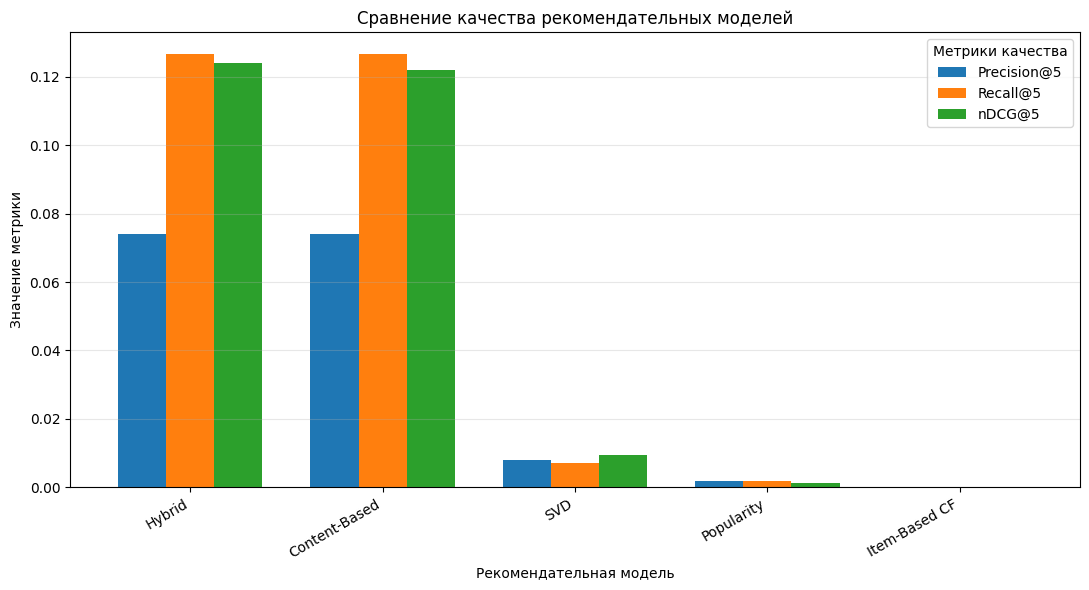

In [64]:

# Визуализация сравнения рекомендательных моделей

ax = final_comparison.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

plt.title("Сравнение качества рекомендательных моделей")
plt.xlabel("Рекомендательная модель")
plt.ylabel("Значение метрики")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Метрики качества")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [65]:

# Финальная проверка проекта

assert len(books) == 10000
assert len(ratings_clean) == 979478
assert len(train) + len(test) == len(ratings_clean)
assert len(train.index.intersection(test.index)) == 0
assert tfidf_matrix.shape[0] == 10000
assert user_book_matrix.nnz == len(train)
assert len(final_comparison) == 5

print("Все проверки пройдены успешно!")
print("Проект готов к сохранению.")


Все проверки пройдены успешно!
Проект готов к сохранению.
